# Experiment 2: RAG Answer Generation & Evaluation
# 本地回答生成与评价

本机实测 RTX 3060 Laptop **6GB**。生成器 Qwen2.5-3B-Instruct；独立自动评分器
Phi-3.5-mini-instruct；均使用 NF4 4-bit。模型放在 D 盘，不需要 API key，也不训练模型。
模型分阶段加载/释放，避免同时占显存。首次部署见 `README_使用说明.md`。

选择 **Legal FAQ (local GPU)** 内核，Restart & Run All。辅助模块与本 notebook 必须同目录。
默认 pilot 为4个 FAQ × 5种查询 × 4组 = 80个回答；正式模式为独立80个 FAQ × 5 × 4 = 1600个。
pilot 只验证流程。正式样本不含 pilot FAQ，也不含与 pilot 完全相同的答案文本。
重复运行会复用已完成记录，失败后可继续。改变协议需新建结果目录，不能混用旧缓存。

## 1. 研究问题和控制变量
RQ1：No-RAG 与三个 RAG 系统的 correctness / relevance 比较。
RQ2：固定 generator、量化、提示词、解码、输出长度，只改变检索上下文；关联检索命中和回答质量。
RQ3：综合检索指标、回答评分、生成耗时及局限。不会预设 Hybrid 最优。

四组为 No-RAG、BM25-RAG、Dense-RAG、RRF-RAG；RAG top-k=5。
每份文档最多240个 generator token；完整输入上限2048，输出最多160 tokens。
同一预算适用于三种检索策略，实际截断的 doc_id 会记录；No-RAG 不接收 gold answer。
greedy decoding（do_sample=False），batch=1。硬件/依赖不同仍可能有小幅数值差异。

In [1]:
import json
import pandas as pd
from IPython.display import display
import rag_pipeline
from model_runtime import ROOT, deployment_report
from rag_pipeline import prepare, generate, judge, report, import_human_review
MODE = 'pilot'  # 改成 'formal' 可运行独立的400条查询；预计耗时见试跑记录。
rag_pipeline.RUN_LABEL = ''  # 修改实验协议时设为 'v2' 等新标签，避免混合旧结果。
display(deployment_report())

{'models': {'generator': {'repo': 'Qwen/Qwen2.5-3B-Instruct',
   'revision': 'aa8e72537993ba99e69dfaafa59ed015b17504d1',
   'path': 'D:\\CodexModels\\LegalFAQ\\hub\\models--Qwen--Qwen2.5-3B-Instruct\\snapshots\\aa8e72537993ba99e69dfaafa59ed015b17504d1'},
  'judge': {'repo': 'microsoft/Phi-3.5-mini-instruct',
   'revision': '2fe192450127e6a83f7441aef6e3ca586c338b77',
   'path': 'D:\\CodexModels\\LegalFAQ\\hub\\models--microsoft--Phi-3.5-mini-instruct\\snapshots\\2fe192450127e6a83f7441aef6e3ca586c338b77'}},
 'cache_dir': 'D:\\CodexModels\\LegalFAQ\\hub',
 'hardware': {'name': 'NVIDIA GeForce RTX 3060 Laptop GPU',
  'total_vram_mb': 6143.5},
 'versions': {'torch': '2.5.1+cu121',
  'transformers': '4.57.6',
  'bitsandbytes': '0.48.2',
  'accelerate': '1.15.0',
  'huggingface-hub': '0.36.2'},
 'quantization': 'NF4 double quantization, FP16 compute, SDPA, batch=1'}

In [2]:
corpus, sample, output_dir, manifest = prepare(MODE)
print(f'{len(sample)} queries; {len(sample) * 4} generated answers')
display(sample.head())

20 queries; 80 generated answers


,query_id,doc_id,query_type,query,corpus_query_index
0,Q002271,1407,original,How does Tamil Nadu Police address issues of h...,2270
1,Q002272,1407,formal,What measures does the Tamil Nadu Police imple...,2271
2,Q002273,1407,casual,How do they handle animal-human clashes in the...,2272
3,Q002274,1407,search,What strategies does the Tamil Nadu Police use...,2273
4,Q002275,1407,hard,How can the Tamil Nadu Police mitigate problem...,2274


## 2. 生成 / Generation
使用 Experiment 1 保存的完整排名，输入数据哈希必须匹配。每条结果原子保存，支持续跑。
保存完整实际证据、引用文档、答案、耗时、token数、峰值显存、输出是否碰到长度上限。
结束后释放生成模型，再开始评分；不要同时运行两个 GPU notebook。

In [3]:
answers = generate(MODE)
display(answers[['query_id', 'system', 'answer', 'seconds', 'hit_token_limit']].head(8))

All generated answers already present; reusing checkpoints.


,query_id,system,answer,seconds,hit_token_limit
0,Q002271,BM25-RAG,Tamil Nadu Police addresses human-animal confl...,13.774966,False
1,Q002271,Dense-RAG,Tamil Nadu Police addresses human-animal confl...,12.445239,False
2,Q002271,No-RAG,"Without specific evidence, I can't provide exa...",7.727462,False
3,Q002271,RRF-RAG,Tamil Nadu Police addresses human-animal confl...,9.596557,False
4,Q002272,BM25-RAG,The Tamil Nadu Police uses the Forest Departme...,7.781393,False
5,Q002272,Dense-RAG,The Tamil Nadu Police addresses human-animal c...,8.690125,False
6,Q002272,No-RAG,"Without specific evidence, I can't provide exa...",7.122579,False
7,Q002272,RRF-RAG,The Tamil Nadu Police works with the Forest De...,8.656987,False


## 3. 独立自动评分 / Provisional automatic evaluation
使用另一模型家族 Phi，不让 generator 给自己打分。评分者不接收系统名称，但能看到有无证据。
correctness：相对 reference 的正确性与完整性；relevance：是否回答 query；
faithfulness：事实性主张是否由实际检索证据支持。每项0/1/2，见 `rag_pipeline.JUDGE_SYSTEM`。
No-RAG 的 faithfulness 为 N/A；纯拒答且无事实主张也为 N/A，不能记作完美忠实。
自动评分不是法律事实核验，也不是已验证金标准；参考答案自身可能有错误。
格式错误会重试一次，仍失败则保留 invalid，不能自动填0冒充有效评分。

In [4]:
judge(MODE)

All judge records already present.


## 4. 汇总、配对区间与人工校准
导出总表、按 query_type 分组表、配对 FAQ bootstrap CI、检索命中和回答质量关联表。
token F1 只是词汇重合代理，不当作 accuracy。报告各指标有效数量；缺失评分可能造成选择偏差。
自动评分为0–2序数分数，均值仅作描述，不应直接称为准确率。
pilot 只有4个 FAQ 群组，区间很不稳定，不用于论文结论。

           correctness  relevance  faithfulness  reference_token_f1_proxy   seconds  input_tokens  output_tokens  hit_token_limit  invalid_citation_count  n_answers  n_valid_correctness  n_valid_relevance  n_valid_faithfulness  n_valid_reference_token_f1_proxy
system                                                                                                                                                                                                                                                              
BM25-RAG      1.947368   1.947368          2.00                  0.528539  7.966733         430.4          61.75              0.0                    0.00         20                   19                 19                    19                                20
Dense-RAG     2.000000   2.000000          2.00                  0.527643  7.829798         404.8          61.30              0.0                    0.00         20                   20                 20             

,correctness,relevance,faithfulness,reference_token_f1_proxy,seconds,input_tokens,output_tokens,hit_token_limit,invalid_citation_count,n_answers,n_valid_correctness,n_valid_relevance,n_valid_faithfulness,n_valid_reference_token_f1_proxy
system,,,,,,,,,,,,,,
BM25-RAG,1.9474,1.9474,2.00,0.5285,7.9667,430.4,61.75,0.0,0.00,20,19,19,19,20
Dense-RAG,2.0000,2.0000,2.00,0.5276,7.8298,404.8,61.30,0.0,0.00,20,20,20,20,20
No-RAG,1.1000,1.3000,NaN,0.2537,5.3020,125.9,41.60,0.0,0.35,20,20,20,0,20
RRF-RAG,1.9500,1.9500,1.95,0.5340,7.5622,421.0,59.25,0.0,0.00,20,20,20,20,20


,system,judge_status,count
0,BM25-RAG,invalid,1
1,BM25-RAG,ok,19
2,Dense-RAG,ok,20
3,No-RAG,ok,20
4,RRF-RAG,ok,20


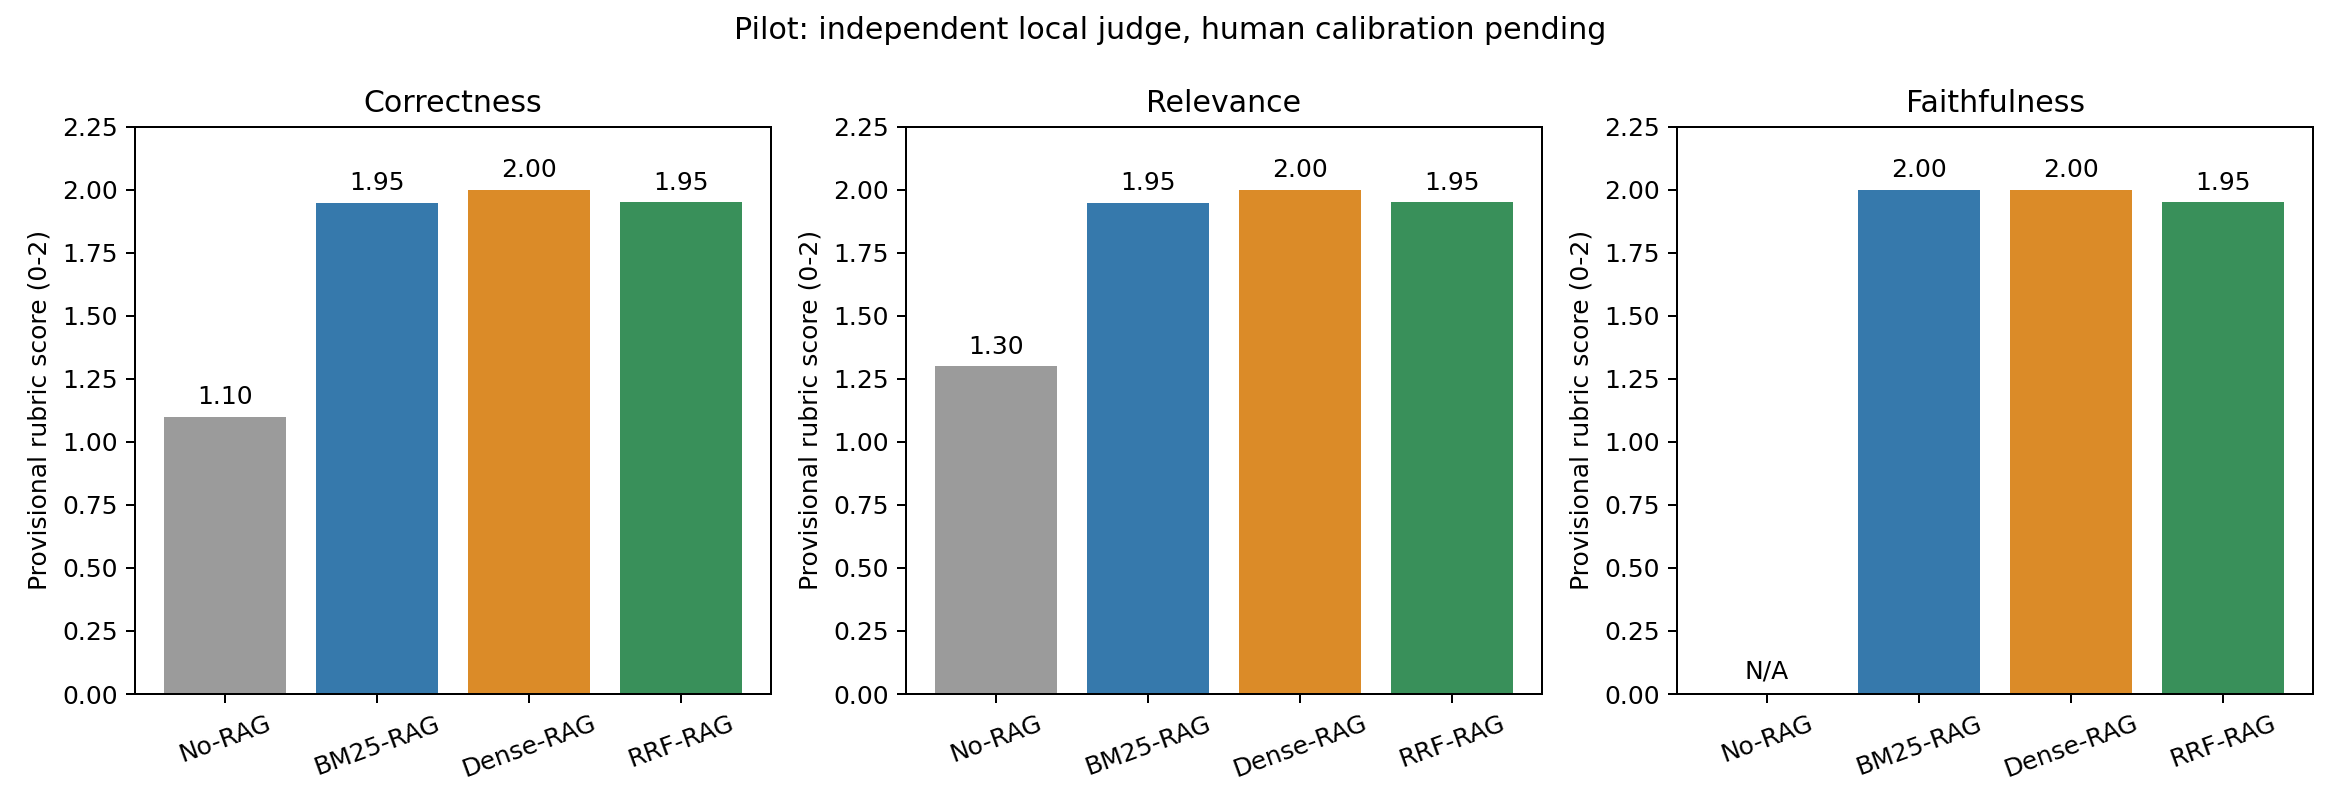

In [5]:
summary = report(MODE)
display(summary.round(4))
display(pd.read_csv(output_dir / 'judge_coverage.csv'))
from IPython.display import Image
display(Image(filename=str(output_dir / 'answer_quality_comparison.png')))

In [6]:
evaluated = pd.read_csv(output_dir / 'answer_evaluation.csv')
display(evaluated[['query_id', 'system', 'correctness', 'relevance', 'faithfulness', 'judge_reason']].head(12))

,query_id,system,correctness,relevance,faithfulness,judge_reason
0,Q002271,BM25-RAG,2.0,2.0,2.0,Candidate answer accurately reflects the refer...
1,Q002271,Dense-RAG,2.0,2.0,2.0,Candidate answer directly addresses the questi...
2,Q002271,No-RAG,1.0,1.0,NaN,Candidate answer is relevant but lacks direct ...
3,Q002271,RRF-RAG,2.0,2.0,2.0,Candidate answer accurately reflects the metho...
4,Q002272,BM25-RAG,2.0,2.0,2.0,Candidate answer directly addresses the questi...
5,Q002272,Dense-RAG,2.0,2.0,2.0,Candidate answer directly addresses the questi...
6,Q002272,No-RAG,1.0,1.0,NaN,Candidate answer is relevant but lacks direct ...
7,Q002272,RRF-RAG,2.0,2.0,2.0,Candidate answer directly addresses the questi...
8,Q002273,BM25-RAG,NaN,NaN,NaN,NaN
9,Q002273,Dense-RAG,2.0,2.0,2.0,Candidate answer accurately reflects the handl...


## 5. 人工复核与后续案例
填写 `human_review_blinded.csv` 的 human_* 列，0/1/2；N/A保留空白并写 notes。
随机排列且隐藏系统与机器分数，映射独立保存在 human_review_key.csv。
先独立评分，再查看自动评分；使用下方代码生成一致性统计。
空白审核表不会伪装成已完成研究；完整论文需报告审核规则、样本量和分歧。

NZ外部案例仍需要经过来源核实的问题、参考答案和检索文档。尚未提供这些数据，
当前输出不能声称验证了新西兰公共服务泛化性。请按 `NZ_Case_Study_Protocol.md` 准备。

In [7]:
calibration = import_human_review(MODE)
display(calibration)
print('n_paired_reviews = 0 means the human audit is not yet completed.')

,metric,n_paired_reviews,exact_agreement,mean_absolute_difference
0,correctness,0,None,None
1,relevance,0,None,None
2,faithfulness,0,None,None


n_paired_reviews = 0 means the human audit is not yet completed.
